<a href="https://colab.research.google.com/github/krishna-murari23/UGRP2026/blob/main/RK_Hybrid_PINNs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid RK-PINN for Transient Heat Diffusion
 A standard (continuous-time) PINN takes `(x, y, t)` as input and gets the time derivative of the temperature by automatic differentiation. The *RK-PINN* instead keeps autograd for the **spatial** derivatives only, and replaces the time derivative with a classical Runge–Kutta / Crank–Nicolson formula inside the loss.

The heat equation is

$$\frac{\partial T}{\partial t} = F(T), \qquad F(T)=\sum_i c_i \frac{\partial^2 T}{\partial x_i^2}$$

where the $c_i$ are the (dimensionless) diffusion coefficients. The network is evaluated at time levels $t_n$ and $t_{n+1}=t_n+\Delta t$, with $T^n \equiv T_\theta(\mathbf{x}, t_n)$. Automatic differentiation is used **only for the spatial derivatives** inside $F$; the time derivative is replaced by any RK formulae.

$$\frac{\partial T}{\partial t} = F(T), \qquad F(T)=\sum_i c_i\,\frac{\partial^2 T}{\partial x_i^2},$$

and $T^{n}\equiv T_\theta(\mathbf{x},t_n)$, $t_{n+1}=t_n+\Delta t$, the residuals $r$ that the loss drives to zero are:

$$\text{Continuous PINN:}\quad r=\frac{\partial T_\theta}{\partial t}-F(T_\theta)$$

$$\text{RK1 (implicit Euler):}\quad r=\frac{T^{n+1}-T^{n}}{\Delta t}-F\!\left(T^{n+1}\right)$$

$$\text{RK2 (Crank–Nicolson):}\quad r=\frac{T^{n+1}-T^{n}}{\Delta t}-\frac12\Big[F\!\left(T^{n+1}\right)+F\!\left(T^{n}\right)\Big]$$

$$\text{RK4 (implicit, Lobatto IIIA):}\quad
\begin{aligned}
r_{\rm mid}&=\frac{T^{n+1/2}-T^{n}}{\Delta t}-\Big(\tfrac{5}{24}F^{n}+\tfrac13F^{n+1/2}-\tfrac1{24}F^{n+1}\Big)\\
r_{\rm end}&=\frac{T^{n+1}-T^{n}}{\Delta t}-\Big(\tfrac16F^{n}+\tfrac23F^{n+1/2}+\tfrac16F^{n+1}\Big)
\end{aligned}$$

**Contents.** 1 Setup · 2 Shared building blocks · 3 Finite-volume reference solver · 4 Case 1 (2D forward) · 5 Case 2 (2D inverse, find $c_p$) · 6 Case 3 (3D battery cell) · 7 Summary.


* The real thermocouple measurements and COMSOL results are not available here. So we uses **synthetic "thermocouple" data generated by our own finite-volume solver** at 19 sensor locations for Case 3.
* Epoch counts are lower. Every knob is in one `CFG` dictionary.
* In Case 2 the unknown `cp` is a trainable parameter updated by Adam (autograd) instead of scheduled finite-difference rule

## 1. Setup



In [ ]:
import copy, time
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from scipy.sparse import diags, identity, kron
from scipy.sparse.linalg import splu
from scipy.interpolate import RegularGridInterpolator

QUICK = False   # True -> tiny networks / few epochs, only checks that the notebook runs

if QUICK:
    CFG = dict(w1=32,  ep1=300,   nf1=500,  w3=32,  ep3=100,  nf3=500,  ep2=600,   nf2=500)
else:
    CFG = dict(w1=256, ep1=10001, nf1=4000, w3=101, ep3=1500, nf3=6000, ep2=15001, nf2=4000)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
results = {}          # we collect headline numbers here for the final summary
print("device:", device, "| QUICK =", QUICK)

device: cuda | QUICK = False


## 2. Shared building blocks

Defines the network used in every case. `MLP` is a fully connected network of $L$ hidden layers,
$$\mathbf{a}^{(l)}=\sigma\!\big(W^{(l)}\mathbf{a}^{(l-1)}+\mathbf{b}^{(l)}\big),\qquad T_\theta=W^{(L+1)}\mathbf{a}^{(L)}+\mathbf{b}^{(L+1)},$$
with Xavier initialisation. Inputs are first rescaled to $[-1,1]$ using the domain bounds,
$$\tilde{\mathbf{x}}=2\,\frac{\mathbf{x}-\mathbf{x}_{\rm lo}}{\mathbf{x}_{\rm hi}-\mathbf{x}_{\rm lo}}-1,$$
inside the model, so autograd still differentiates with respect to the original coordinates. This matters most for the thin 3D cell. `ScaledTanh` is the activation $\sigma(x)=\tanh(0.5\,x)$ used in Case 2; Cases 1 and 3 use SiLU.

In [ ]:
class ScaledTanh(nn.Module):
    def forward(self, x):
        return torch.tanh(0.5 * x)

class MLP(nn.Module):

    def __init__(self, n_in, n_hidden, width, act, lo, hi):
        super().__init__()
        self.register_buffer("lo", torch.tensor(lo, dtype=torch.float32))   # domain lower bounds
        self.register_buffer("hi", torch.tensor(hi, dtype=torch.float32))   # domain upper bounds
        layers, d_in = [], n_in
        for _ in range(n_hidden):
            layers += [nn.Linear(d_in, width), act()]
            d_in = width
        layers.append(nn.Linear(d_in, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:                                  # Xavier initialisation
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, *coords):
        z = torch.cat(coords, dim=1)
        z = 2 * (z - self.lo) / (self.hi - self.lo) - 1      # rescale inputs to [-1, 1]
        return self.net(z)

Two small helpers. `d(f, x)` returns the first derivative $\partial f/\partial x$ by autograd, keeping the graph so it can be differentiated again. `F_op` builds the spatial operator of the heat equation,
$$F(T)=\sum_i c_i\,\frac{\partial^2 T}{\partial x_i^2},$$
where the coefficients $c_i$ carry the Fourier number or diffusivity ratios. One function therefore serves 2D and 3D, isotropic and orthotropic problems.

In [ ]:
def d(f, x):
    """First derivative df/dx via autograd (graph kept so we can differentiate again)."""
    return torch.autograd.grad(f, x, torch.ones_like(f), create_graph=True)[0]

def F_op(T, coords, coefs):
    """Spatial diffusion operator  F(T) = sum_i coef_i * d2T/dx_i2."""
    return sum(c * d(d(T, x), x) for x, c in zip(coords, coefs))

There are 2 different residual methods :`residual_continuous` is the standard PINN, $r=\partial_t T_\theta-F(T_\theta)$, with the time derivative from autograd. `residual_scheme` is the RK-PINN: it evaluates the same network at $t_n$ and $t_n+\Delta t$ and applies the RK1, RK2 or RK4 formula given in the introduction, so autograd is never taken with respect to time. For RK4 the network is also evaluated at $t_n+\Delta t/2$ and the two stage residuals $r_{\rm mid}$ and $r_{\rm end}$ are stacked.

In [ ]:
def residual_continuous(model, coords, t, coefs):
    """Standard PINN:  dT/dt - F(T) = 0, with dT/dt from autograd."""
    T = model(*coords, t)
    return d(T, t) - F_op(T, coords, coefs)

def residual_scheme(model, coords, t_n, dt, coefs, scheme):
    """RK-PINN: time derivative replaced by a time-stepping formula between t_n and t_n + dt."""
    T_n   = model(*coords, t_n)
    T_np1 = model(*coords, t_n + dt)
    if scheme == "rk1":                                   # implicit Euler
        return (T_np1 - T_n) / dt - F_op(T_np1, coords, coefs)
    if scheme == "rk2":                                   # Crank-Nicolson
        return (T_np1 - T_n) / dt - 0.5 * (F_op(T_np1, coords, coefs) + F_op(T_n, coords, coefs))
    if scheme == "rk4":                                   # 4th-order implicit (Lobatto IIIA, 3 stages)
        T_mid = model(*coords, t_n + 0.5 * dt)
        k1, k2, k3 = (F_op(T, coords, coefs) for T in (T_n, T_mid, T_np1))
        r_mid = (T_mid - T_n) / dt - (5 / 24 * k1 + 1 / 3 * k2 - 1 / 24 * k3)   # stage at t_n + dt/2
        r_end = (T_np1 - T_n) / dt - (1 / 6 * k1 + 2 / 3 * k2 + 1 / 6 * k3)     # update to t_n + dt
        return torch.cat([r_mid, r_end], dim=0)
    raise ValueError(scheme)

## 3. Reference solver: a small finite-volume code

We use a reference solver as a ground truth all cases and also generates the synthetic measurements for Cases 2 and 3.

It is a cell-centred finite-volume scheme on a box grid. For a cell of volume $V$,
$$\rho c_p V\,\frac{dT}{dt}=\sum_{\rm neighbours}G\,(T_{\rm nb}-T)+\text{boundary terms},\qquad G=\frac{k_a V}{d_a^{2}},$$
where $d_a$ is the cell size along axis $a$. A boundary face is adiabatic, carries a prescribed inward flux $q$, or loses heat by convection with the effective coefficient
$$h_{\rm eff}=\left(\frac{d_a}{2k_a}+\frac1h\right)^{-1}.$$
Writing the semi-discrete system as $\dot{\mathbf T}=A\mathbf T+\mathbf b$, time stepping is Crank–Nicolson,
$$\Big(I-\tfrac{\Delta t}{2}A\Big)\mathbf T^{n+1}=\Big(I+\tfrac{\Delta t}{2}A\Big)\mathbf T^{n}+\Delta t\,\mathbf b,$$
with one sparse LU factorisation reused at every step. A 2D problem is a grid with two cells in $z$ and adiabatic $z$ faces.

Defines `fv_solve`. The 1D matrix `lap1d` has adiabatic ends and the 3D matrix is the Kronecker sum of three of them. Each boundary face listed in `faces` adds its flux and convection terms. The function returns the saved times and the temperature fields, of shape `(n_saved, nx, ny, nz)`, and `cell_centres` gives the cell-centre coordinates.

In [ ]:
def fv_solve(n, L, k, rho_cp, T0, t_end, dt, faces, save_every=None, save_times=None):
    """Crank-Nicolson finite-volume solver."""
    nx, ny, nz = n
    dx = [L[i] / n[i] for i in range(3)]
    c = [k[i] / (rho_cp * dx[i] ** 2) for i in range(3)]          # diffusion rates per axis

    def lap1d(m, ci):                                              # adiabatic 1D Laplacian
        main = -2 * np.ones(m); main[0] = main[-1] = -1.0
        return ci * diags([np.ones(m - 1), main, np.ones(m - 1)], [-1, 0, 1])
    I = [identity(m) for m in n]
    A = (kron(kron(lap1d(nx, c[0]), I[1]), I[2]) +
         kron(kron(I[0], lap1d(ny, c[1])), I[2]) +
         kron(kron(I[0], I[1]), lap1d(nz, c[2])))

    diag, b = np.zeros(n), np.zeros(n)                              # boundary contributions
    axis_side = {"x0": (0, 0), "x1": (0, -1), "y0": (1, 0), "y1": (1, -1), "z0": (2, 0), "z1": (2, -1)}
    for name, bc in faces.items():
        ax, side = axis_side[name]
        idx = [slice(None)] * 3; idx[ax] = side; idx = tuple(idx)  # boundary layer of cells
        q, Tinf = bc.get("q", 0.0), bc.get("Tinf", 0.0)
        h = np.asarray(bc.get("h", 0.0), dtype=float)
        h_eff = np.where(h > 0, 1.0 / (dx[ax] / (2 * k[ax]) + 1.0 / np.maximum(h, 1e-12)), 0.0)
        diag[idx] += -h_eff / (rho_cp * dx[ax])                     # -h_eff*T term
        b[idx] += (q + h_eff * Tinf) / (rho_cp * dx[ax])            # flux + h_eff*Tinf term
    A = (A + diags(diag.ravel())).tocsc()

    N = A.shape[0]
    lu = splu((identity(N) - 0.5 * dt * A).tocsc())                 # factorise once
    M2 = (identity(N) + 0.5 * dt * A).tocsc()
    T = np.array(T0, dtype=float).ravel()
    times, fields = [], []

    def store(step, t):
        if (save_every and step % save_every == 0) or (save_times is not None and
                any(abs(t - ts) < 1e-6 for ts in save_times)):
            times.append(t); fields.append(T.reshape(n).copy())
    store(0, 0.0)
    for step in range(1, int(round(t_end / dt)) + 1):
        T = lu.solve(M2 @ T + dt * b.ravel())
        store(step, step * dt)
    return np.array(times), np.array(fields)

def cell_centres(n, L):
    return [(np.arange(n[i]) + 0.5) * L[i] / n[i] for i in range(3)]

Sanity check of the solver. For a slab heated by a constant flux $q$ on one face with all other faces adiabatic, the mean temperature rise must equal $q\,t/(\rho c_p L_x)$. The two printed numbers should agree.

In [ ]:
n_t, L_t = (40, 20, 2), (1.0, 1.0, 1.0)
tt, ff = fv_solve(n_t, L_t, (45, 45, 45), 100 * 100, np.zeros(n_t), 100.0, 1.0,
                  {"x0": dict(q=1000.0)}, save_times=[100.0])
expected = 1000.0 * 1.0 * 100.0 / (100 * 100 * 1.0)         # q*t/(rho*cp*Lx)  (uniform heating of a slab)
print("mean rise  (solver)  : %.4f K" % ff[-1].mean())
print("mean rise  (analytic): %.4f K" % expected)

mean rise  (solver)  : 10.0000 K
mean rise  (analytic): 10.0000 K


## 4. Case Study 1 — 2D transient forward problem

A $1\,\text{m}\times1\,\text{m}$ plate starts at a uniform $T_{\rm init}=298.15$ K. A constant flux $q_0=1000$ W/m² heats the left edge and the other three edges cool by convection. Four neural solvers (continuous PINN, RK1, RK2, RK4) are compared with the finite-volume reference.

The problem is non-dimensionalised with
$$x^*=\frac{x}{L},\quad y^*=\frac{y}{L},\quad t^*=\frac{t}{t_{\rm final}},\quad T^*=\frac{T-T_\infty}{\Delta T_{\rm ref}},\quad \Delta T_{\rm ref}=\frac{q_0L}{k},$$
which turns the heat equation into
$$\frac{\partial T^*}{\partial t^*}=Fo\left(\frac{\partial^2T^*}{\partial x^{*2}}+\frac{\partial^2T^*}{\partial y^{*2}}\right),\qquad Fo=\frac{\alpha\,t_{\rm final}}{L^2},\quad Bi=\frac{hL}{k},$$
with the boundary conditions
$$-\frac{\partial T^*}{\partial x^*}\Big|_{x^*=0}=1,\qquad
\frac{\partial T^*}{\partial x^*}\Big|_{x^*=1}=-Bi\,T^*,\qquad
\frac{\partial T^*}{\partial y^*}\Big|_{y^*=1}=-Bi\,T^*,\qquad
\frac{\partial T^*}{\partial y^*}\Big|_{y^*=0}=+Bi\,T^*,$$
and the initial condition $T^*(x^*,y^*,0)=0$.

Physical parameters from Table 4.1 of the thesis, and the dimensionless groups $Fo\approx1.35$ and $Bi\approx0.556$. `DT1` is the physical time step of the RK schemes. DT1 = 5 seconds. Crank–Nicolson is stable for any step value , since it;s implicit

In [ ]:
L1, k1, rho1, cp1 = 1.0, 45.0, 100.0, 100.0        # size, conductivity, density, specific heat
q01, h1, Tinf1, t_final1 = 1000.0, 25.0, 298.15, 300.0
alpha1 = k1 / (rho1 * cp1)                          # thermal diffusivity
dT_ref1 = q01 * L1 / k1                             # temperature scale
Fo1 = alpha1 * t_final1 / L1**2                     # Fourier number  (~1.35)
Bi1 = h1 * L1 / k1                                  # Biot number     (~0.556)

DT1 = 5.0                                           # RK time step in seconds (thesis: 1.0)
dt1 = DT1 / t_final1                                # same step in dimensionless time
print(f"Fo = {Fo1:.3f}, Bi = {Bi1:.3f}, dT_ref = {dT_ref1:.2f} K, dimensionless dt = {dt1:.4f}")

Fo = 1.350, Bi = 0.556, dT_ref = 22.22 K, dimensionless dt = 0.0167


Reference solution from the finite-volume solver ($100\times100$ cells, $\Delta t=1$ s), playing the role of the thesis's FDM baseline. Only the field at $t=300$ s is kept, as `T_ref1`; it is used for error measurement and is never seen during training.

In [ ]:
n1 = (100, 100, 2)
faces1 = {"x0": dict(q=q01),                                    # heated left edge
          "x1": dict(h=h1, Tinf=Tinf1), "y0": dict(h=h1, Tinf=Tinf1), "y1": dict(h=h1, Tinf=Tinf1)}
_, f1 = fv_solve(n1, (L1, L1, 1.0), (k1, k1, k1), rho1 * cp1, np.full(n1, Tinf1),
                 t_final1, 1.0, faces1, save_times=[t_final1])
T_ref1 = f1[-1][:, :, 0]                                        # shape (nx, ny)
print("reference field at t=300 s: min %.2f K, max %.2f K" % (T_ref1.min(), T_ref1.max()))

reference field at t=300 s: min 306.37 K, max 320.24 K


Boundary and initial-condition losses, shared by Cases 1 and 2. `face_eval` samples random points on one edge, at random times, and returns $T$, $\partial T/\partial x$ and $\partial T/\partial y$ there. `bc_loss_2d` is the sum of the squared mismatches of the four conditions above,
$$\mathcal{L}_{\rm BC}=\big\langle(T^*_x+q^*)^2\big\rangle_{\rm left}+\big\langle(T^*_x+Bi_xT^*)^2\big\rangle_{\rm right}+\big\langle(T^*_y+Bi_yT^*)^2\big\rangle_{\rm top}+\big\langle(T^*_y-Bi_yT^*)^2\big\rangle_{\rm bottom},$$
and `ic_loss_2d` is $\mathcal{L}_{\rm IC}=\langle (T^*(x,y,0))^2\rangle$.

In [ ]:
def face_eval(model, n, x=None, y=None):
    """Random points on one edge of the unit square; returns T, dT/dx, dT/dy."""
    t = torch.rand(n, 1, device=device)
    xx = (torch.full((n, 1), x) if x is not None else torch.rand(n, 1)).to(device).requires_grad_(True)
    yy = (torch.full((n, 1), y) if y is not None else torch.rand(n, 1)).to(device).requires_grad_(True)
    T = model(xx, yy, t)
    return T, d(T, xx), d(T, yy)

def bc_loss_2d(model, n, flux, Bi_x, Bi_y):
    T, Tx, _ = face_eval(model, n, x=0.0); l_left   = ((Tx + flux) ** 2).mean()        # -dT/dx = flux
    T, Tx, _ = face_eval(model, n, x=1.0); l_right  = ((Tx + Bi_x * T) ** 2).mean()    #  dT/dx = -Bi T
    T, _, Ty = face_eval(model, n, y=1.0); l_top    = ((Ty + Bi_y * T) ** 2).mean()    #  dT/dy = -Bi T
    T, _, Ty = face_eval(model, n, y=0.0); l_bottom = ((Ty - Bi_y * T) ** 2).mean()    #  dT/dy = +Bi T
    return l_left + l_right + l_top + l_bottom

def ic_loss_2d(model, n):
    x, y = torch.rand(n, 1, device=device), torch.rand(n, 1, device=device)
    return (model(x, y, torch.zeros_like(x)) ** 2).mean()                              # T* = 0 at t = 0

`train_case1(scheme)` trains any of the four solvers (`"continuous"`, `"rk1"`, `"rk2"`, `"rk4"`). Each epoch draws fresh random interior points, computes the PDE residual (with $t_n$ drawn from $[0,1-\Delta t^*]$ for the RK schemes), and takes one Adam step on
$$\mathcal{L}=\mathcal{L}_{\rm PDE}+2\,\mathcal{L}_{\rm BC}+5\,\mathcal{L}_{\rm IC},\qquad \mathcal{L}_{\rm PDE}=\frac1{N_f}\sum_i r_i^{2}.$$
The network has 4 hidden layers of `w1` SiLU neurons; the learning rate starts at $2\times10^{-3}$ and is halved five times during training.

In [ ]:
def train_case1(scheme, epochs=CFG["ep1"], n_f=CFG["nf1"], width=CFG["w1"]):
    torch.manual_seed(0)
    model = MLP(3, 4, width, nn.SiLU, lo=[0, 0, 0], hi=[1, 1, 1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(epochs // 5, 1), gamma=0.5)
    coefs = (Fo1, Fo1)                                           # F(T) = Fo (T_xx + T_yy)
    n_b = max(n_f // 4, 100)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        x = torch.rand(n_f, 1, device=device, requires_grad=True)
        y = torch.rand(n_f, 1, device=device, requires_grad=True)
        if scheme == "continuous":
            t = torch.rand(n_f, 1, device=device, requires_grad=True)
            res = residual_continuous(model, (x, y), t, coefs)
        else:
            t_n = torch.rand(n_f, 1, device=device) * (1 - dt1)
            res = residual_scheme(model, (x, y), t_n, dt1, coefs, scheme)
        l_pde = (res ** 2).mean()
        l_bc = bc_loss_2d(model, n_b, flux=1.0, Bi_x=Bi1, Bi_y=Bi1)
        l_ic = ic_loss_2d(model, n_b)
        loss = l_pde + 2 * l_bc + 5 * l_ic
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        hist.append([loss.item(), l_pde.item(), l_bc.item(), l_ic.item()])
        if ep % max(epochs // 5, 1) == 0:
            print(f"[{scheme:10s}] epoch {ep:6d}  loss {loss.item():.3e}  ({time.time()-t0:.0f}s)")
    return model, np.array(hist)

Trains the four solvers with identical networks, optimiser and number of epochs so the comparison is fair. This is the longest cell of the notebook; RK4 is the slowest scheme because it evaluates the network at three time levels.

In [ ]:
models1, hists1 = {}, {}
for scheme in ["continuous", "rk1", "rk2", "rk4"]:
    models1[scheme], hists1[scheme] = train_case1(scheme)

[continuous] epoch      0  loss 2.011e+00  (2s)
[continuous] epoch   2000  loss 4.207e-03  (130s)
[continuous] epoch   4000  loss 1.733e-03  (262s)
[continuous] epoch   6000  loss 6.483e-04  (399s)
[continuous] epoch   8000  loss 6.281e-04  (534s)
[continuous] epoch  10000  loss 5.931e-04  (668s)
[rk1       ] epoch      0  loss 2.011e+00  (0s)
[rk1       ] epoch   2000  loss 7.855e-03  (124s)
[rk1       ] epoch   4000  loss 8.405e-04  (248s)
[rk1       ] epoch   6000  loss 3.243e-04  (372s)
[rk1       ] epoch   8000  loss 2.747e-04  (495s)
[rk1       ] epoch  10000  loss 2.536e-04  (619s)
[rk2       ] epoch      0  loss 2.011e+00  (0s)
[rk2       ] epoch   2000  loss 4.005e-03  (197s)
[rk2       ] epoch   4000  loss 1.566e-03  (395s)
[rk2       ] epoch   6000  loss 6.927e-04  (591s)
[rk2       ] epoch   8000  loss 5.491e-04  (789s)
[rk2       ] epoch  10000  loss 5.776e-04  (985s)
[rk4       ] epoch      0  loss 2.011e+00  (0s)
[rk4       ] epoch   2000  loss 2.962e-03  (276s)
[rk4    

Predicts the temperature at $t=300$ s on the reference's cell centres and converts back to Kelvin with $T=T_\infty+\Delta T_{\rm ref}\,T^*$. For each method it prints the mean and maximum of the absolute error $|T_{\rm ref}-T_\theta|$.

In [ ]:
def predict_2d(model, t_star, n=100):
    xs = (torch.arange(n, dtype=torch.float32) + 0.5) / n
    X, Y = torch.meshgrid(xs, xs, indexing="ij")
    x, y = X.reshape(-1, 1).to(device), Y.reshape(-1, 1).to(device)
    with torch.no_grad():
        Ts = model(x, y, torch.full_like(x, t_star))
    return Ts.reshape(n, n).cpu().numpy()

pred1, err1 = {}, {}
print(f"{'method':12s} {'mean |err| (K)':>15s} {'max |err| (K)':>15s}")
for s, m in models1.items():
    pred1[s] = Tinf1 + dT_ref1 * predict_2d(m, 1.0)
    err1[s] = np.abs(pred1[s] - T_ref1)
    print(f"{s:12s} {err1[s].mean():15.4f} {err1[s].max():15.4f}")
    results[f"Case1 {s} mean error (K)"] = err1[s].mean()

method        mean |err| (K)   max |err| (K)
continuous            0.0105          0.0296
rk1                   0.0511          0.0584
rk2                   0.0029          0.0147
rk4                   0.0165          0.0269


Temperature fields at $t=300$ s: the reference on the left, then the four neural solvers, all on the same colour scale.

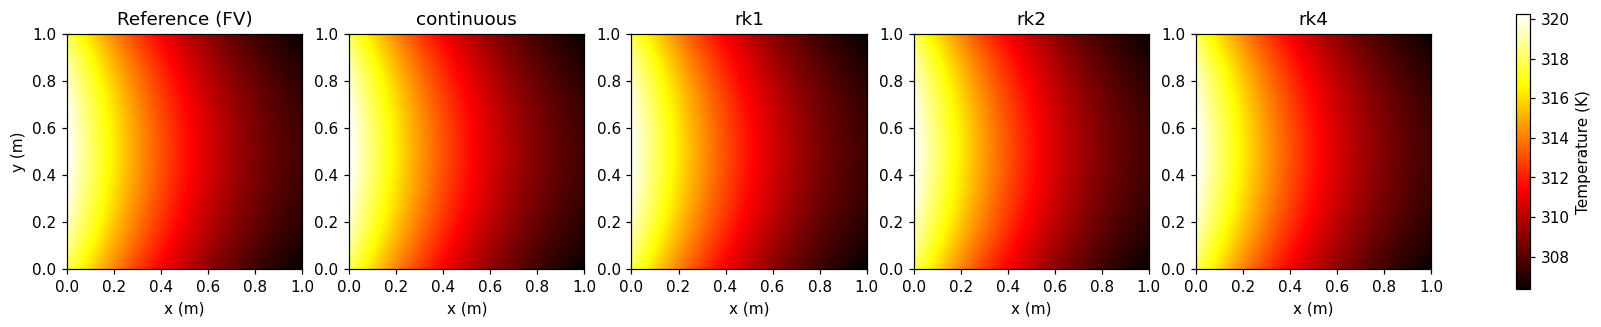

In [ ]:
fig, axs = plt.subplots(1, 5, figsize=(20, 3.6))
vmin, vmax = T_ref1.min(), T_ref1.max()
for ax, (name, field) in zip(axs, [("Reference (FV)", T_ref1)] + [(s, pred1[s]) for s in pred1]):
    im = ax.imshow(field.T, origin="lower", extent=[0, 1, 0, 1], cmap="hot", vmin=vmin, vmax=vmax)
    ax.set_title(name); ax.set_xlabel("x (m)")
axs[0].set_ylabel("y (m)")
fig.colorbar(im, ax=axs, label="Temperature (K)", shrink=0.9)
plt.show()

Absolute error maps $|T_{\rm ref}-T_\theta|$ for the four solvers on a common colour scale, with the mean error in each title.

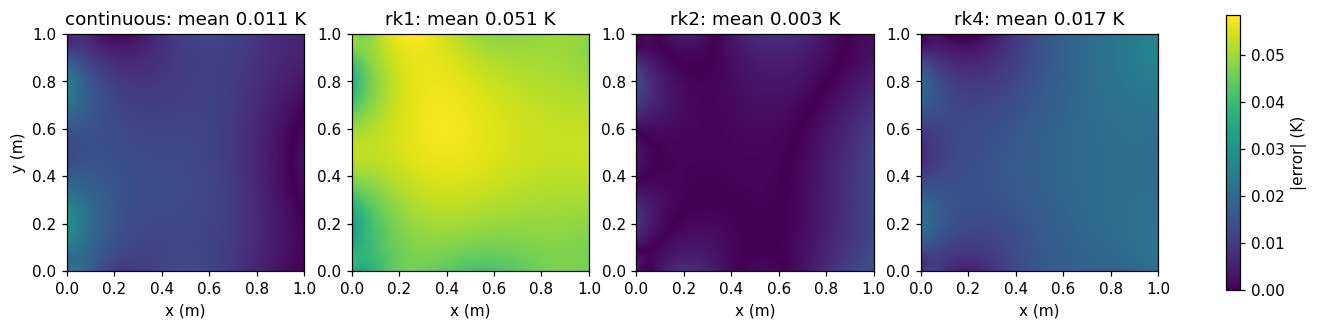

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6))
emax = max(e.max() for e in err1.values())
for ax, s in zip(axs, err1):
    im = ax.imshow(err1[s].T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis", vmin=0, vmax=emax)
    ax.set_title(f"{s}: mean {err1[s].mean():.3f} K"); ax.set_xlabel("x (m)")
axs[0].set_ylabel("y (m)")
fig.colorbar(im, ax=axs, label="|error| (K)", shrink=0.9)
plt.show()

Total training loss of each solver against epoch, smoothed with a short moving average and drawn on a logarithmic axis.

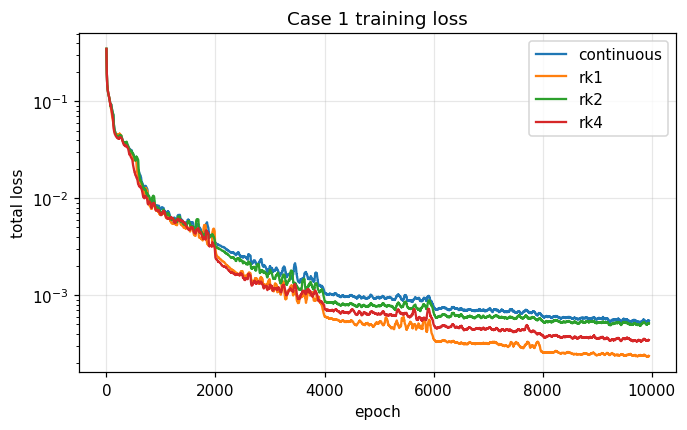

In [ ]:
def smooth(a, w=50):
    w = min(w, len(a)); return np.convolve(a, np.ones(w) / w, mode="valid")

plt.figure(figsize=(7, 4))
for s, h_ in hists1.items():
    plt.semilogy(smooth(h_[:, 0]), label=s)
plt.xlabel("epoch"); plt.ylabel("total loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Case 1 training loss"); plt.show()

## 5. Case Study 2 — 2D transient inverse problem (find $c_p$)

The plate is now orthotropic ($k_x=21$, $k_y=3$ W/m·K), the specific heat $c_p$ is unknown, and instead of knowing everything we have 580 sparse temperature measurements. The true value is $c_p=100$ J/(kg·K) and the initial guess is 140. With $x^*=x/L$, $t^*=t/t_{\rm end}$ and $T^*=(T-T_\infty)/\Delta T_{\rm norm}$ the equation is
$$\frac{\partial T^*}{\partial t^*}=c_x\left[\frac{\partial^2T^*}{\partial x^{*2}}+\frac{k_y}{k_x}\frac{\partial^2T^*}{\partial y^{*2}}\right],\qquad c_x=\frac{t_{\rm end}\,k_x}{\rho\,c_p\,L^2},$$
so $c_p$ enters through the coefficients of $F$, which is how it receives gradients. The boundary conditions are those of Case 1 with
$$q^*=\frac{qL}{k_x\Delta T_{\rm norm}},\qquad Bi_x=\frac{hL}{k_x},\qquad Bi_y=\frac{hL}{k_y}.$$

Parameters from Table 4.2 of the thesis, including the starting guess for $c_p$. `DT2` is the RK time step in seconds. `NOISE_STD` adds Gaussian noise (in Kelvin) to the synthetic measurements; leave it at 0 for the clean case.

In [ ]:
L2, kx2, ky2, rho2 = 1.0, 21.0, 3.0, 100.0
q2, h2, Tinf2, t_end2, dT2 = 500.0, 15.0, 300.0, 200.0, 40.0
CP_TRUE, CP_INIT = 100.0, 140.0
DT2 = 5.0                         # RK time step in seconds
dt2 = DT2 / t_end2                # dimensionless
NOISE_STD = 0.0                   # K, noise on the synthetic measurements

Generates the "experimental" data. The thesis supplies a CSV of 580 points; here the problem is solved with the true $c_p=100$ and five probes along $y=0.5$ ($x=0.1,\dots,0.9$) are sampled at 116 times between 1 s and 200 s, giving $5\times116=580$ measurements. The full solution is kept as the ground-truth field. To use your own data, replace `xd, yd, td, Td` (m, m, s, K) by the columns of your file.

In [ ]:
n2 = (60, 60, 2)
faces2 = {"x0": dict(q=q2), "x1": dict(h=h2, Tinf=Tinf2),
          "y0": dict(h=h2, Tinf=Tinf2), "y1": dict(h=h2, Tinf=Tinf2)}
t_fv2, f_fv2 = fv_solve(n2, (L2, L2, 1.0), (kx2, ky2, ky2), rho2 * CP_TRUE, np.full(n2, Tinf2),
                        t_end2, 0.5, faces2, save_every=1)            # keep every step

probes = np.array([[0.1, 0.5], [0.3, 0.5], [0.5, 0.5], [0.7, 0.5], [0.9, 0.5]])
t_samp = np.linspace(1.0, t_end2, 116)
xc2, yc2, zc2 = cell_centres(n2, (L2, L2, 1.0))
pts = np.c_[probes, np.full(len(probes), 0.5)]
series = np.array([RegularGridInterpolator((xc2, yc2, zc2), f, bounds_error=False, fill_value=None)(pts)
                   for f in f_fv2])                                    # (n_times, n_probes)
rows = []
for j, (px, py) in enumerate(probes):
    Tj = np.interp(t_samp, t_fv2, series[:, j])
    rows += [(px, py, ts, T_) for ts, T_ in zip(t_samp, Tj)]
rows = np.array(rows)
rows[:, 3] += NOISE_STD * np.random.randn(len(rows))
xd, yd, td, Td = rows.T
print("number of measurements:", len(rows))

# tensors in dimensionless form for the loss
xd_t, yd_t = [torch.tensor(a, dtype=torch.float32, device=device).reshape(-1, 1) for a in (xd, yd)]
td_t = torch.tensor(td / t_end2, dtype=torch.float32, device=device).reshape(-1, 1)
Td_t = torch.tensor((Td - Tinf2) / dT2, dtype=torch.float32, device=device).reshape(-1, 1)

number of measurements: 580


`train_case2(scheme)` trains the inverse problem. The specific heat is stored as $c_p=100\,p$ with $p$ a trainable scalar of order one, updated by its own Adam learning rate. The PDE coefficients are rebuilt from the current $c_p$ at every epoch, so the residual, continuous or Crank–Nicolson, is differentiable with respect to $c_p$. The loss is
$$\mathcal{L}=\mathcal{L}_{\rm PDE}+\mathcal{L}_{\rm BC}+10\,\mathcal{L}_{\rm IC}+10\,\mathcal{L}_{\rm data},\qquad \mathcal{L}_{\rm data}=\frac1{N_{\rm data}}\sum_i\big(T^*_\theta(\mathbf x_i,t_i)-T^*_{{\rm meas},i}\big)^2,$$
and $c_p$ is recorded at every epoch so the convergence of the two methods can be compared.

In [ ]:
def train_case2(scheme, epochs=CFG["ep2"], n_f=CFG["nf2"]):
    torch.manual_seed(0)
    model = MLP(3, 8, 31, ScaledTanh, lo=[0, 0, 0], hi=[1, 1, 1]).to(device)
    CP_SCALE = 100.0
    p = nn.Parameter(torch.tensor(CP_INIT / CP_SCALE, device=device))          # cp = CP_SCALE * p
    opt = torch.optim.Adam([{"params": model.parameters(), "lr": 1e-3},
                            {"params": [p], "lr": 2e-3}])
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(epochs // 4, 1), gamma=0.5)
    n_b = max(n_f // 4, 100)
    cp_hist, loss_hist, t0 = [], [], time.time()
    for ep in range(epochs):
        cp = CP_SCALE * p
        cx = t_end2 * kx2 / (rho2 * cp * L2**2)                                 # PDE coefficients depend on cp
        coefs = (cx, cx * ky2 / kx2)
        x = torch.rand(n_f, 1, device=device, requires_grad=True)
        y = torch.rand(n_f, 1, device=device, requires_grad=True)
        if scheme == "continuous":
            t = torch.rand(n_f, 1, device=device, requires_grad=True)
            res = residual_continuous(model, (x, y), t, coefs)
        else:
            t_n = torch.rand(n_f, 1, device=device) * (1 - dt2)
            res = residual_scheme(model, (x, y), t_n, dt2, coefs, scheme)
        l_pde = (res ** 2).mean()
        l_bc = bc_loss_2d(model, n_b, flux=q2 * L2 / (kx2 * dT2), Bi_x=h2 * L2 / kx2, Bi_y=h2 * L2 / ky2)
        l_ic = ic_loss_2d(model, n_b)
        l_data = ((model(xd_t, yd_t, td_t) - Td_t) ** 2).mean()
        loss = l_pde + l_bc + 10 * l_ic + 10 * l_data
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        cp_hist.append(cp.item()); loss_hist.append(loss.item())
        if ep % max(epochs // 5, 1) == 0:
            print(f"[{scheme:10s}] epoch {ep:6d}  loss {loss.item():.3e}  cp = {cp.item():7.2f}  ({time.time()-t0:.0f}s)")
    return model, np.array(cp_hist), np.array(loss_hist)

Trains the standard inverse PINN and the RK2 inverse PINN with identical settings and the same number of epochs.

In [ ]:
models2, cp2, loss2 = {}, {}, {}
for scheme in ["continuous", "rk2"]:
    models2[scheme], cp2[scheme], loss2[scheme] = train_case2(scheme)

[continuous] epoch      0  loss 5.914e-01  cp =  140.00  (0s)
[continuous] epoch   3000  loss 4.207e-02  cp =  126.43  (156s)
[continuous] epoch   6000  loss 2.412e-02  cp =  129.39  (307s)
[continuous] epoch   9000  loss 2.057e-02  cp =  132.36  (458s)
[continuous] epoch  12000  loss 1.667e-02  cp =  133.04  (610s)
[continuous] epoch  15000  loss 1.538e-02  cp =  134.49  (761s)
[rk2       ] epoch      0  loss 5.914e-01  cp =  140.00  (0s)
[rk2       ] epoch   3000  loss 4.225e-02  cp =  126.65  (199s)
[rk2       ] epoch   6000  loss 2.398e-02  cp =  129.43  (394s)
[rk2       ] epoch   9000  loss 1.967e-02  cp =  131.88  (590s)
[rk2       ] epoch  12000  loss 1.644e-02  cp =  133.13  (787s)
[rk2       ] epoch  15000  loss 1.529e-02  cp =  134.27  (985s)


In [ ]:
def epochs_to_within(cp_curve, tol=0.02):
    ok = np.abs(cp_curve - CP_TRUE) / CP_TRUE < tol
    bad = np.where(~ok)[0]
    return 0 if len(bad) == 0 else (bad[-1] + 1 if bad[-1] + 1 < len(ok) else None)

print(f"true cp = {CP_TRUE}, initial guess = {CP_INIT}")
for s in cp2:
    final = cp2[s][-200:].mean()
    ep_ok = epochs_to_within(cp2[s])
    print(f"{s:11s}: final cp = {final:7.2f}  (error {100*abs(final-CP_TRUE)/CP_TRUE:5.2f} %),  "
          f"within 2% from epoch: {ep_ok}")
    results[f"Case2 {s} final cp"] = final

true cp = 100.0, initial guess = 140.0
continuous : final cp =  134.42  (error 34.42 %),  within 2% from epoch: None
rk2        : final cp =  134.20  (error 34.20 %),  within 2% from epoch: None


Left: the trajectory of the $c_p$ estimate for both methods, with the true value as a dashed line. Right: the smoothed total loss.

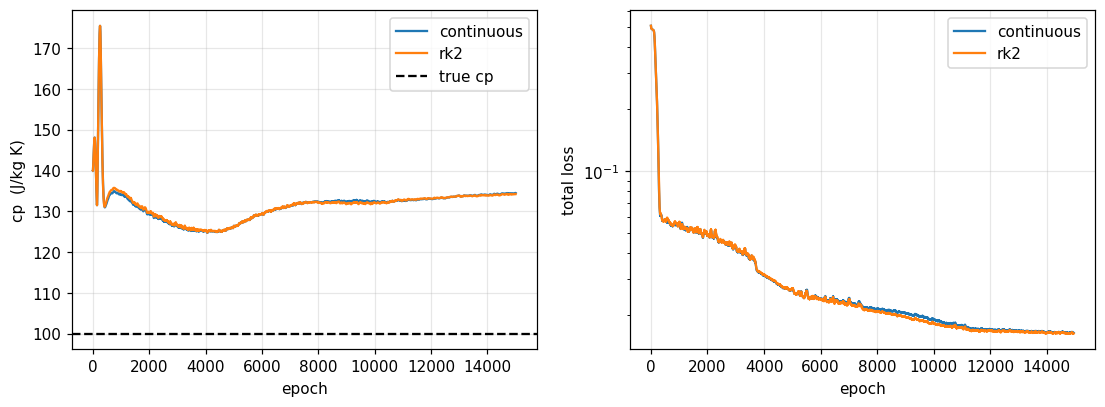

In [ ]:
def smooth(a, w=50):
    w = min(w, len(a))
    return np.convolve(a, np.ones(w) / w, mode="valid")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for s in cp2:
    axs[0].plot(cp2[s], label=s); axs[1].semilogy(smooth(loss2[s]), label=s)
axs[0].axhline(CP_TRUE, color="k", ls="--", label="true cp")
axs[0].set_xlabel("epoch"); axs[0].set_ylabel("cp  (J/kg K)"); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[1].set_xlabel("epoch"); axs[1].set_ylabel("total loss"); axs[1].legend(); axs[1].grid(alpha=0.3)
plt.show()

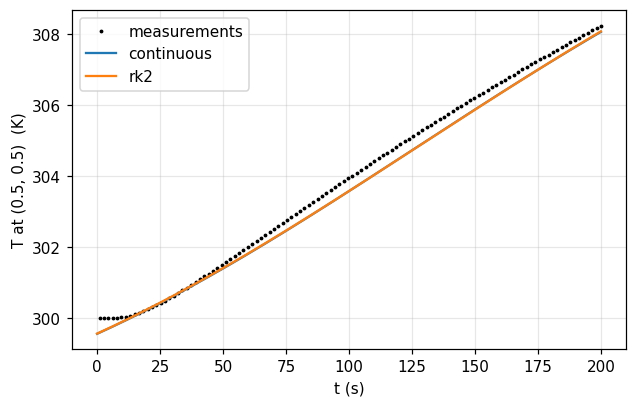

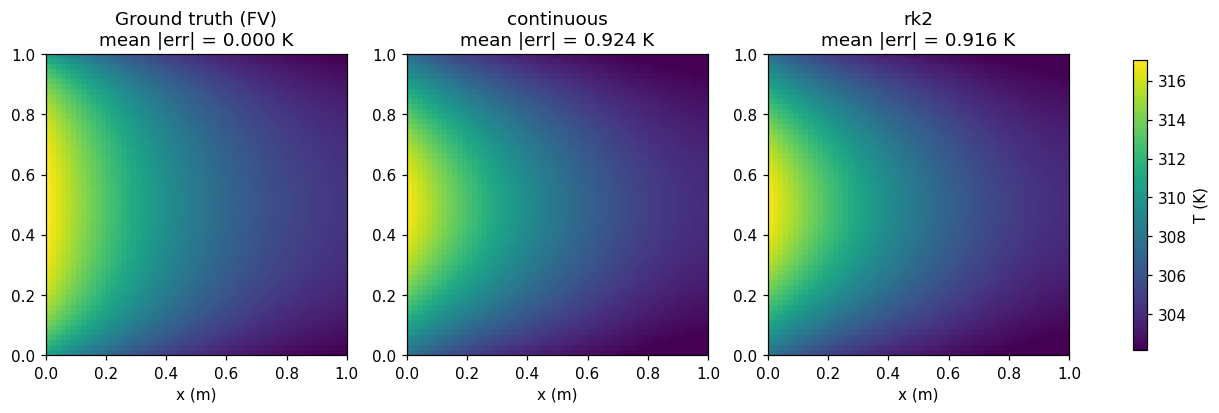

In [ ]:
def pred_point(model, x, y, t_s):
    n = len(t_s)
    X = torch.full((n, 1), x, device=device); Y = torch.full((n, 1), y, device=device)
    T_ = torch.tensor(t_s / t_end2, dtype=torch.float32, device=device).reshape(-1, 1)
    with torch.no_grad():
        return Tinf2 + dT2 * model(X, Y, T_).cpu().numpy().ravel()

t_plot = np.linspace(0, t_end2, 200)
plt.figure(figsize=(6.5, 4))
m = np.isclose(xd, 0.5)
plt.plot(td[m], Td[m], "k.", ms=3, label="measurements")
for s in models2:
    plt.plot(t_plot, pred_point(models2[s], 0.5, 0.5, t_plot), label=s)
plt.xlabel("t (s)"); plt.ylabel("T at (0.5, 0.5)  (K)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# 2D field at t = 200 s
n_g = 60
xs = (torch.arange(n_g, dtype=torch.float32) + 0.5) / n_g
X, Y = torch.meshgrid(xs, xs, indexing="ij")
xg, yg = X.reshape(-1, 1).to(device), Y.reshape(-1, 1).to(device)
fields2 = {"Ground truth (FV)": f_fv2[-1][:, :, 0]}
for s, mdl in models2.items():
    with torch.no_grad():
        fields2[s] = Tinf2 + dT2 * mdl(xg, yg, torch.ones_like(xg)).reshape(n_g, n_g).cpu().numpy()
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
vmin, vmax = fields2["Ground truth (FV)"].min(), fields2["Ground truth (FV)"].max()
for ax, (name, fld) in zip(axs, fields2.items()):
    im = ax.imshow(fld.T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis", vmin=vmin, vmax=vmax)
    err = np.abs(fld - fields2["Ground truth (FV)"]).mean()
    ax.set_title(f"{name}\nmean |err| = {err:.3f} K"); ax.set_xlabel("x (m)")
fig.colorbar(im, ax=axs, label="T (K)", shrink=0.9); plt.show()

## 6. Case Study 3 — 3D anisotropic battery cell (forward problem with sparse sensors)

A pouch cell of size $0.168\times0.0073\times0.225$ m is heated by a $30\times30$ mm patch heater with $q_{\rm in}=10\,200$ W/m². Conduction is strong in-plane ($k_x=k_z=21$ W/m·K) and weak through the thickness ($k_y=3$ W/m·K). The aim is to reconstruct the 3D temperature and heat-flux fields over 50 s from only 19 thermocouple readings.

Here the network input is only $(x^*,y^*,z^*)$; time is not an input. The network represents the field at one time level and the solution is marched forward: a frozen copy of the previous network supplies $T^n$, and the new network is trained so that $T^{n+1}$ satisfies the Crank–Nicolson residual
$$r=\frac{T^{n+1}-T^{n}}{\Delta t^*}-\frac12\Big[F\!\left(T^{n+1}\right)+F\!\left(T^{n}\right)\Big],$$
the boundary conditions, and the data when sensors exist at that time. Only three spatial dimensions ever enter autograd.

The heater and the convective condition are applied on the face $y=0$; the thesis text calls it the back face, but its sign conventions only work if the outward normal is $-y$. The opposite face $y=W$ is adiabatic.

Parameters from Table 4.3 and the non-dimensionalisation,
$$\mathbf{x}^*=\frac{\mathbf{x}}{l_{\max}},\quad t^*=\frac{t}{t_{\rm ref}},\quad T^*=\frac{T-T_\infty}{\Delta T_{\rm norm}},\qquad l_{\max}=0.225\ \text{m},\ t_{\rm ref}=50\ \text{s},\ \Delta T_{\rm norm}=2\ \text{K}.$$
The coefficients of $F$ in $(x,y,z)$ order are $A_i=\dfrac{t_{\rm ref}}{l_{\max}^{2}}\,\dfrac{k_i}{\rho c_p}$, the target heater gradient is
$$q^*=\frac{q_{\rm in}\,l_{\max}}{k_y\,\Delta T_{\rm norm}},$$
and the convective condition uses $Bi=h\,l_{\max}/k_y$. `DT3` is the Crank–Nicolson step; the thesis samples sensors every 10 s and 5 s steps are used here so every second step has data.

In [ ]:
Lx3, Wy3, Hz3 = 0.168, 0.0073, 0.225
kx3, ky3, kz3 = 21.0, 3.0, 21.0
rho3, cp3 = 1600.0, 1800.0
q_in3, h3, Tinf3 = 10200.0, 15.0, 299.3
patch_x, patch_z = (0.069, 0.099), (0.0975, 0.1275)       # heater patch on the y = 0 face (metres)
t_ref3, dT3, l_max3 = 50.0, 2.0, 0.225
DT3 = 5.0                                                  # Crank-Nicolson step (s)
N_STEPS3 = int(t_ref3 / DT3)

X_S, Y_S, Z_S = Lx3 / l_max3, Wy3 / l_max3, Hz3 / l_max3   # dimensionless box
dt_star3 = DT3 / t_ref3
pref = t_ref3 / l_max3**2
ax3, ay3 = kx3 / (rho3 * cp3), ky3 / (rho3 * cp3)
A3 = (pref * ax3, pref * ay3, pref * ax3)                  # coefficients of F for (x, y, z)
q_star3 = q_in3 * l_max3 / (ky3 * dT3)                     # target heater gradient (large!)
Bi3 = h3 * l_max3 / ky3
px0, px1, pz0, pz1 = patch_x[0]/l_max3, patch_x[1]/l_max3, patch_z[0]/l_max3, patch_z[1]/l_max3
print(f"dimensionless box = {X_S:.3f} x {Y_S:.4f} x {Z_S:.3f};  heater gradient = {q_star3:.1f};  Bi = {Bi3:.3f}")

dimensionless box = 0.747 x 0.0324 x 1.000;  heater gradient = 382.5;  Bi = 1.125


Synthetic ground truth and thermocouple data. The same problem is solved with the finite-volume code ($56\times5\times75$ cells, $\Delta t=1$ s) as a stand-in for COMSOL, with the heater flux on the patch cells and convection elsewhere on that face. Then 19 virtual thermocouples (10 on the heater face $y=0$, 9 on the opposite face) are read every 10 s from 0 to 50 s. To use real measurements, overwrite `sensors` (19 × 3 array in metres), `TC_TIMES` (s) and `TC_DATA` (shape `(len(TC_TIMES), 19)`, K) after this cell.

In [ ]:
n3 = (56, 5, 75)
xc3, yc3, zc3 = cell_centres(n3, (Lx3, Wy3, Hz3))
in_patch = ((xc3[:, None] >= patch_x[0]) & (xc3[:, None] <= patch_x[1]) &
            (zc3[None, :] >= patch_z[0]) & (zc3[None, :] <= patch_z[1]))        # (nx, nz) mask
faces3 = {"y0": dict(q=np.where(in_patch, q_in3, 0.0),                           # heater patch: flux
                     h=np.where(in_patch, 0.0, h3), Tinf=Tinf3)}                 # elsewhere: convection
t_fv3, f_fv3 = fv_solve(n3, (Lx3, Wy3, Hz3), (kx3, ky3, kz3), rho3 * cp3, np.full(n3, Tinf3),
                        t_ref3, 1.0, faces3, save_every=1)
interp3 = lambda f, P: RegularGridInterpolator((xc3, yc3, zc3), f, bounds_error=False, fill_value=None)(P)

# 19 virtual thermocouples: (x, z) pairs on the heater face (y=0) and on the opposite face (y=W)
xz_front = [(0.084,0.122),(0.084,0.100),(0.070,0.1125),(0.098,0.1125),(0.084,0.150),
            (0.084,0.075),(0.040,0.1125),(0.130,0.1125),(0.084,0.190),(0.120,0.050)]
xz_back  = [(0.084,0.1125),(0.084,0.135),(0.070,0.100),(0.098,0.125),(0.084,0.160),
            (0.050,0.1125),(0.120,0.1125),(0.084,0.060),(0.030,0.030)]
sensors = np.array([(x_, 0.0, z_) for x_, z_ in xz_front] + [(x_, Wy3, z_) for x_, z_ in xz_back])
TC_TIMES = np.arange(0.0, 50.1, 10.0)
TC_DATA = np.array([interp3(f_fv3[np.argmin(np.abs(t_fv3 - tt))], sensors) for tt in TC_TIMES])  # (6, 19)
print("sensors:", sensors.shape, "| data:", TC_DATA.shape, "| max rise at a sensor: %.2f K" % (TC_DATA.max() - Tinf3))

sensors: (19, 3) | data: (6, 19) | max rise at a sensor: 15.97 K


Converts the sensor data to dimensionless form and defines the boundary losses. The conditions are
$$\frac{\partial T^*}{\partial x^*}=0\ \ (x^*=0,X_S),\qquad \frac{\partial T^*}{\partial z^*}=0\ \ (z^*=0,Z_S),\qquad \frac{\partial T^*}{\partial y^*}=0\ \ (y^*=Y_S),$$
$$\frac{\partial T^*}{\partial y^*}=-q^*\ \ (y^*=0,\ \text{inside the patch}),\qquad \frac{\partial T^*}{\partial y^*}=Bi\,T^*\ \ (y^*=0,\ \text{outside the patch}).$$
The adiabatic conditions use squared errors and the heater and convective conditions use absolute errors, as in the thesis. `face_points3` samples random points on a face and `bc_losses_3d` returns the five loss terms.

In [ ]:
tc_xyz = torch.tensor(sensors / l_max3, dtype=torch.float32, device=device)                 # (19, 3)
tc_T = torch.tensor((TC_DATA - Tinf3) / dT3, dtype=torch.float32, device=device)             # (6, 19)

def face_points3(n, fixed=None, value=0.0, box=None):
    """n random points in the dimensionless box (or on one face of it); returns [x, y, z] needing grad."""
    lo_hi = box or {"x": (0, X_S), "y": (0, Y_S), "z": (0, Z_S)}
    p = {a: lo_hi[a][0] + torch.rand(n, 1) * (lo_hi[a][1] - lo_hi[a][0]) for a in "xyz"}
    if fixed: p[fixed] = torch.full((n, 1), value)
    return [p[a].to(device).requires_grad_(True) for a in "xyz"]

def bc_losses_3d(model, n):
    mse = lambda a: (a ** 2).mean()
    l_x = l_z = 0.0
    for v in (0.0, X_S):                                   # x faces adiabatic
        x, y, z = face_points3(n, "x", v); l_x = l_x + mse(d(model(x, y, z), x))
    for v in (0.0, Z_S):                                   # z faces adiabatic
        x, y, z = face_points3(n, "z", v); l_z = l_z + mse(d(model(x, y, z), z))
    x, y, z = face_points3(n, "y", Y_S)                    # opposite face adiabatic
    l_adia = mse(d(model(x, y, z), y))
    x, y, z = face_points3(n, "y", 0.0)                    # heater face, convective part (outside patch)
    T = model(x, y, z)
    outside = (~((x >= px0) & (x <= px1) & (z >= pz0) & (z <= pz1))).float().detach()
    l_conv = ((d(T, y) - Bi3 * T).abs() * outside).sum() / outside.sum().clamp(min=1)
    x, y, z = face_points3(n, "y", 0.0, box={"x": (px0, px1), "y": (0, Y_S), "z": (pz0, pz1)})   # heater patch
    l_heat = (d(model(x, y, z), y) + q_star3).abs().mean()
    return l_x + l_z, l_adia, l_conv, l_heat

The time-marching trainer. For each of the 10 steps it freezes a copy of the current network as $T^n$ (zero for the first step), warm-starts from the previous weights, and minimises
$$\mathcal{L}=100\,\mathcal{L}_{\rm PDE}+0.1\,\mathcal{L}_{\rm sides}+10\,\mathcal{L}_{\rm adia}+4\,\mathcal{L}_{\rm conv}+2.4\,\mathcal{L}_{\rm heater}+0.1\,\mathcal{L}_{\rm data},$$
where $\mathcal{L}_{\rm PDE}$ is the Crank–Nicolson residual at random interior points with $F(T^n)$ evaluated by the frozen network, and $\mathcal{L}_{\rm data}$ is the mean absolute mismatch at the 19 sensors, added only when sensor data exist at the end of that step. The first two steps get twice as many epochs because the large heater gradient must be learned first. After each step the probe temperature is recorded and the network is frozen.

In [ ]:
probe3 = np.array([0.084, 0.0, 0.122])                       # point on the heater face inside the patch

def train_case3(epochs=CFG["ep3"], n_f=CFG["nf3"], width=CFG["w3"]):
    torch.manual_seed(0)
    model = MLP(3, 4, width, nn.SiLU, lo=[0, 0, 0], hi=[X_S, Y_S, Z_S]).to(device)
    prev, probe_hist, t0 = None, [(0.0, Tinf3)], time.time()
    n_b = max(n_f // 6, 200)
    for step in range(N_STEPS3):
        t_new = (step + 1) * DT3
        k_data = [i for i, tt in enumerate(TC_TIMES) if abs(tt - t_new) < 1e-6]    # data at this time?
        opt = torch.optim.Adam(model.parameters(), lr=8e-4)
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(epochs // 3, 1), gamma=0.5)
        n_ep = 2 * epochs if step < 2 else epochs                                    # extra epochs while the heater gradient is first learned
        for ep in range(n_ep):
            x, y, z = face_points3(n_f)                                             # interior points
            T1 = model(x, y, z)
            if prev is None:
                Tn, Fn = torch.zeros_like(T1), torch.zeros_like(T1)                 # initial state T* = 0
            else:
                Tn_ = prev(x, y, z); Fn = F_op(Tn_, (x, y, z), A3).detach(); Tn = Tn_.detach()
            res = (T1 - Tn) / dt_star3 - 0.5 * (F_op(T1, (x, y, z), A3) + Fn)       # Crank-Nicolson residual
            l_pde = (res ** 2).mean()
            l_side, l_adia, l_conv, l_heat = bc_losses_3d(model, n_b)
            loss = 100 * l_pde + 0.1 * l_side + 10 * l_adia + 4 * l_conv + 2.4 * l_heat
            if k_data:
                pred = model(tc_xyz[:, 0:1], tc_xyz[:, 1:2], tc_xyz[:, 2:3]).squeeze()
                l_data = (pred - tc_T[k_data[0]]).abs().mean()
                loss = loss + 0.1 * l_data
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        prev = copy.deepcopy(model)                                                 # freeze T^{n+1}
        for p_ in prev.parameters(): p_.requires_grad_(False)
        with torch.no_grad():
            pt = torch.tensor(probe3 / l_max3, dtype=torch.float32, device=device)
            T_probe = Tinf3 + dT3 * model(pt[0:1].view(1, 1), pt[1:2].view(1, 1), pt[2:3].view(1, 1)).item()
        probe_hist.append((t_new, T_probe))
        print(f"step {step+1:2d}/{N_STEPS3}  t = {t_new:4.0f} s  loss {loss.item():.3e}  probe {T_probe:7.2f} K  ({time.time()-t0:.0f}s)")
    return model, np.array(probe_hist)

Runs the 3D RK2-PINN. Every step starts from the previous network's weights, so later steps converge faster.

In [ ]:
model3, probe_hist3 = train_case3()

step  1/10  t =    5 s  loss 1.575e+02  probe  304.97 K  (164s)
step  2/10  t =   10 s  loss 1.417e+02  probe  310.08 K  (354s)
step  3/10  t =   15 s  loss 7.736e+01  probe  312.19 K  (448s)
step  4/10  t =   20 s  loss 5.700e+01  probe  314.01 K  (555s)
step  5/10  t =   25 s  loss 4.948e+01  probe  315.49 K  (660s)
step  6/10  t =   30 s  loss 4.010e+01  probe  316.65 K  (761s)
step  7/10  t =   35 s  loss 4.359e+01  probe  317.60 K  (860s)
step  8/10  t =   40 s  loss 3.001e+01  probe  318.41 K  (960s)
step  9/10  t =   45 s  loss 3.106e+01  probe  319.09 K  (1054s)
step 10/10  t =   50 s  loss 3.693e+01  probe  319.71 K  (1151s)


Numerical checks. It prints the mean and maximum absolute temperature error on the heater face at $t=50$ s against the finite-volume reference, the peak temperature of both, the RMSE at the 19 sensors, and the recovered heater gradient $\partial T/\partial y$ at the patch centre, which should be close to $-q_{\rm in}/k_y=-3400$ K/m.

In [ ]:
dy3 = Wy3 / n3[1]
Xg, Zg = np.meshgrid(xc3, zc3, indexing="ij")                      # (56, 75) face grid
def eval_face(model, y_m):
    """T (K), dT/dx, dT/dy, dT/dz (K/m) on the face grid at depth y_m."""
    x = torch.tensor(Xg.reshape(-1, 1) / l_max3, dtype=torch.float32, device=device).requires_grad_(True)
    z = torch.tensor(Zg.reshape(-1, 1) / l_max3, dtype=torch.float32, device=device).requires_grad_(True)
    y = torch.full_like(x, y_m / l_max3).requires_grad_(True)
    T = model(x, y, z)
    g = [d(T, v) for v in (x, y, z)]
    out = [Tinf3 + dT3 * T] + [dT3 / l_max3 * gi for gi in g]
    return [o.detach().cpu().numpy().reshape(Xg.shape) for o in out]

T_p, dTdx_p, dTdy_p, dTdz_p = eval_face(model3, dy3 / 2)
T_fv_face = f_fv3[-1][:, 0, :]                                     # first layer of cells at t = 50 s
err3 = np.abs(T_p - T_fv_face)
print("heater-face temperature error vs reference: mean %.3f K, max %.3f K" % (err3.mean(), err3.max()))
print("peak temperature  reference %.2f K | PINN %.2f K" % (T_fv_face.max(), T_p.max()))

with torch.no_grad():
    s_ = torch.tensor(sensors / l_max3, dtype=torch.float32, device=device)
    T_sens = Tinf3 + dT3 * model3(s_[:, 0:1], s_[:, 1:2], s_[:, 2:3]).cpu().numpy().ravel()
print("RMSE at the 19 sensors, t = 50 s: %.3f K" % np.sqrt(np.mean((T_sens - TC_DATA[-1]) ** 2)))

ic_ = (np.argmin(np.abs(xc3 - 0.084)), np.argmin(np.abs(zc3 - 0.1125)))
print("dT/dy at patch centre: PINN %.0f K/m | expected -q/ky = %.0f K/m" % (dTdy_p[ic_], -q_in3 / ky3))
results["Case3 mean face error (K)"] = err3.mean()
results["Case3 sensor RMSE (K)"] = np.sqrt(np.mean((T_sens - TC_DATA[-1]) ** 2))

heater-face temperature error vs reference: mean 0.536 K, max 6.314 K
peak temperature  reference 315.21 K | PINN 318.71 K
RMSE at the 19 sensors, t = 50 s: 2.937 K
dT/dy at patch centre: PINN -3001 K/m | expected -q/ky = -3400 K/m


Temperature on the heater face at $t=50$ s: reference (left), RK2-PINN (middle) and absolute error (right). White dots mark the thermocouples on this face.

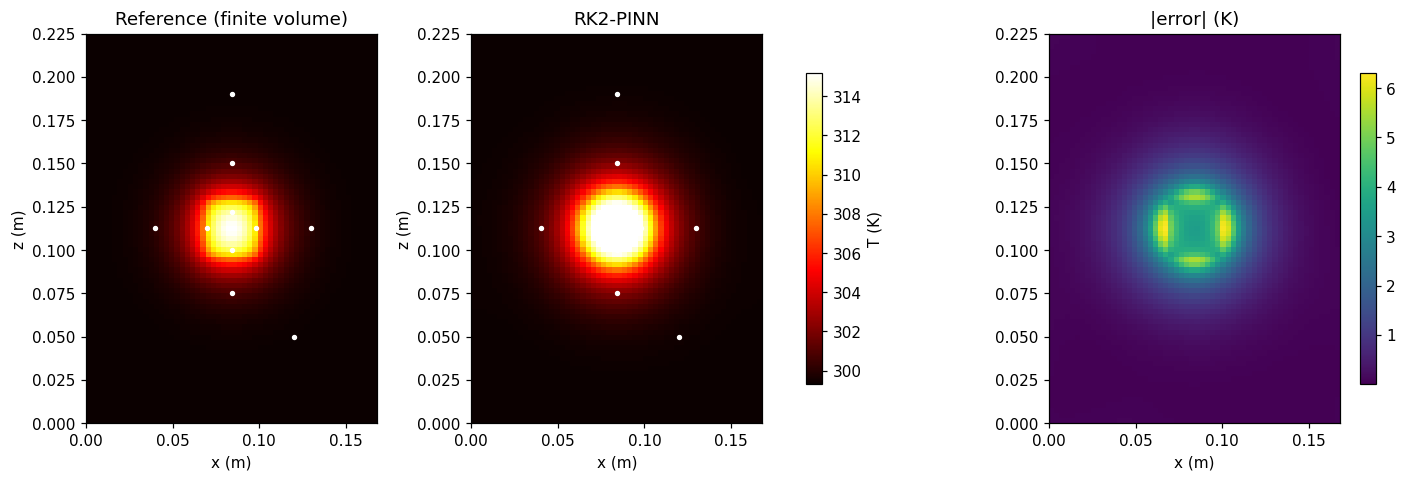

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
vmin, vmax = T_fv_face.min(), T_fv_face.max()
for ax, fld, ttl in zip(axs[:2], [T_fv_face, T_p], ["Reference (finite volume)", "RK2-PINN"]):
    im = ax.pcolormesh(xc3, zc3, fld.T, cmap="hot", vmin=vmin, vmax=vmax, shading="auto"); ax.set_title(ttl)
    ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)"); ax.set_aspect("equal")
    fs = sensors[sensors[:, 1] == 0.0]; ax.plot(fs[:, 0], fs[:, 2], "w.", ms=5)
fig.colorbar(im, ax=axs[:2], label="T (K)", shrink=0.8)
im = axs[2].pcolormesh(xc3, zc3, err3.T, cmap="viridis", shading="auto"); axs[2].set_title("|error| (K)")
axs[2].set_xlabel("x (m)"); axs[2].set_aspect("equal"); fig.colorbar(im, ax=axs[2], shrink=0.8)
plt.show()

Temperature history at a probe point on the heater patch: the reference curve at every second, the RK2-PINN value after each marching step, and the virtual thermocouple readings.

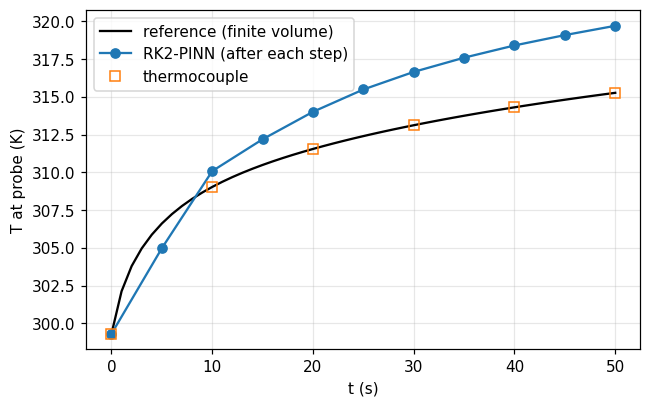

error at t = 50 s: 4.44 K


In [ ]:
i_probe = np.argmin(np.linalg.norm(sensors - probe3, axis=1))
ref_curve = [interp3(f, probe3[None, :])[0] for f in f_fv3]
plt.figure(figsize=(6.5, 4))
plt.plot(t_fv3, ref_curve, "k-", label="reference (finite volume)")
plt.plot(probe_hist3[:, 0], probe_hist3[:, 1], "o-", label="RK2-PINN (after each step)")
plt.plot(TC_TIMES, TC_DATA[:, i_probe], "s", mfc="none", label="thermocouple")
plt.xlabel("t (s)"); plt.ylabel("T at probe (K)"); plt.legend(); plt.grid(alpha=0.3); plt.show()
print("error at t = 50 s: %.2f K" % abs(probe_hist3[-1, 1] - ref_curve[-1]))

Directional temperature gradients on the heater face at $t=50$ s, which show where heat flows since $q=-k\,\partial T/\partial n$. Top row: reference; bottom row: RK2-PINN. The $\partial T/\partial y$ panel should show a strongly negative square on the heater patch, and $\partial T/\partial x$ and $\partial T/\partial z$ should show edge dipoles where heat spreads sideways. The reference gradients are finite differences of the first cell layer, so magnitudes near the patch edges differ slightly.

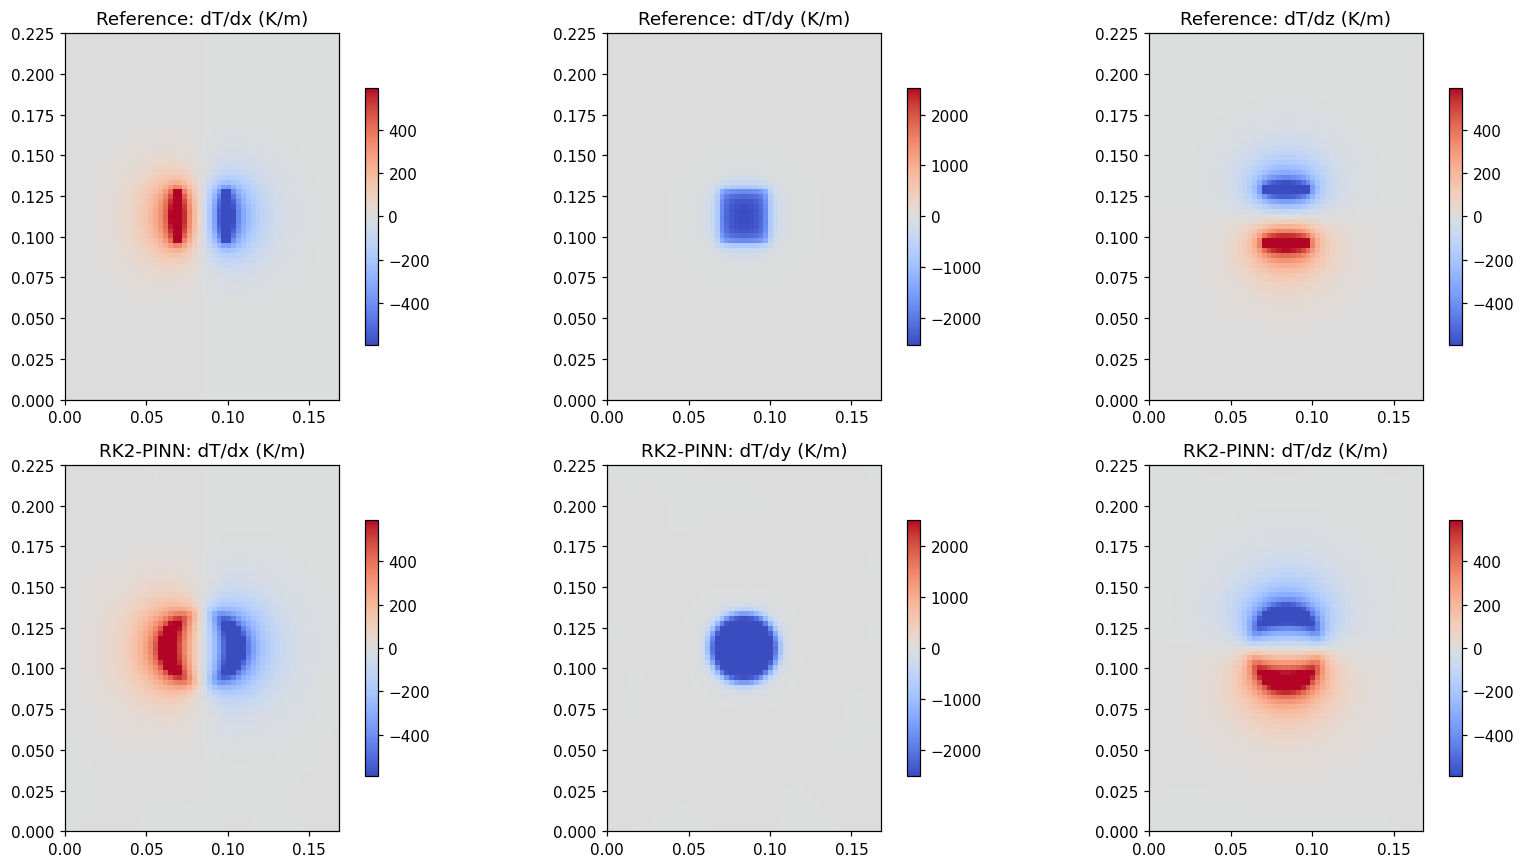

In [ ]:
fv_dx = np.gradient(T_fv_face, xc3, axis=0)
fv_dz = np.gradient(T_fv_face, zc3, axis=1)
fv_dy = (f_fv3[-1][:, 1, :] - f_fv3[-1][:, 0, :]) / dy3
rows_ = [("Reference", [fv_dx, fv_dy, fv_dz]), ("RK2-PINN", [dTdx_p, dTdy_p, dTdz_p])]
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for r, (name, fl) in enumerate(rows_):
    for c_, (g, lab) in enumerate(zip(fl, ["dT/dx", "dT/dy", "dT/dz"])):
        lim = np.percentile(np.abs(np.concatenate([fv_dx.ravel(), fv_dz.ravel()])), 99) if lab != "dT/dy" else np.abs(fv_dy).max()
        im = axs[r, c_].pcolormesh(xc3, zc3, g.T, cmap="coolwarm", vmin=-lim, vmax=lim, shading="auto")
        axs[r, c_].set_title(f"{name}: {lab} (K/m)"); axs[r, c_].set_aspect("equal")
        fig.colorbar(im, ax=axs[r, c_], shrink=0.7)
plt.tight_layout(); plt.show()

## 7. Summary

Prints the headline numbers collected in `results`. Compare them with the claims of the thesis. In Case 1, whether the RK variants beat the continuous PINN depends on the step `DT1` and the number of epochs, and RK4 and RK2 are expected to differ little at small dimensionless steps. In Case 2 both methods use the same number of epochs, so the comparison is about how fast and how stably $c_p$ approaches 100. In Case 3 the continuous 4D PINN baseline is not re-run; only the RK2 time-marching solver is reproduced, against synthetic sensors.

In [ ]:
print(f"{'quantity':45s} value")
for key, val in results.items():
    print(f"{key:45s} {val:.4f}")